# Mall Customers (Kaggle): clustering

200 customers with age, annual income and spending score (Kaggle), standardized. No labels, so only internal scores judge the clusters.

Every method is tuned by the shared, label-free rule (`sc4020.tuning`); labels are used only for the
external scores. Sections: dataset loading, one section per method, metrics, visualization. Tables go to
`results/datasets/mall_customers_results.csv` and `mall_customers_tuning.csv`, figures to `results/datasets/figures/`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sc4020 import run, tuning
from sc4020.datasets import load_dataset

warnings.filterwarnings("ignore")
np.random.seed(run.SEED)

DATASET_NAME = "mall_customers"
TOPIC = "datasets"
MAX_CLUSTERS = None  # optional cap on the number of DBSCAN and HDBSCAN clusters

## 1. Dataset loading

In [2]:
ds = load_dataset(DATASET_NAME)
k_range = run.K_RANGES.get(DATASET_NAME, tuning.K_RANGE)
print(ds.DESCR)
print(f"{len(ds.data):,} points, {ds.data.shape[1]} features, classes: {ds.n_true_clusters}")
pd.DataFrame(ds.data, columns=ds.feature_names).describe().round(2)

Kaggle Mall Customers: 200 x 3 (age, income, spending score), no labels. Standardized.
200 points, 3 features, classes: None


,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00
mean,-0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-1.50,-1.74,-1.91
25%,-0.72,-0.73,-0.60
50%,-0.20,0.04,-0.01
75%,0.73,0.67,0.89
max,2.24,2.92,1.89


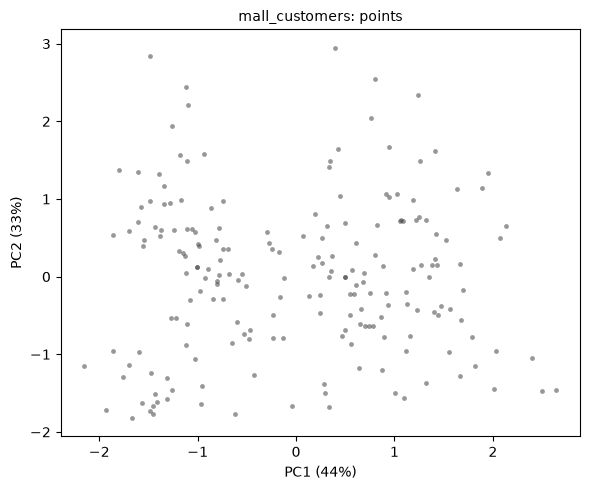

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/mall_customers_data.png')

In [3]:
from sc4020.generate_figures import plot_coords, scatter_labels, show_and_save
x, y, x_label, y_label = plot_coords(ds)
fig, ax = plt.subplots(figsize=(6, 5))
scatter_labels(
    ax,
    np.column_stack([x, y]),
    ds.target,
    title=f"{DATASET_NAME}: {'classes' if ds.target is not None else 'points'}",
    class_names=ds.get("target_names"),
    size=2 if len(ds.data) > 5000 else 12,
)
ax.set_xlabel(x_label)
ax.set_ylabel(y_label)
fig.tight_layout()
show_and_save(fig, TOPIC, f"{DATASET_NAME}_data")

## 2. Clustering with K-Means

The number of clusters k comes from the fake-data check: for each k, the silhouette on the real data
minus the mean silhouette on copies with every column shuffled, among the k whose seeds agree. On
labelled data K-Means uses the true number of classes, and the label-free choice is shown next to it.
Plain K-Means starts from random centres; K-Means++ (next section) uses the same k.

In [4]:
selections, results = {}, {}
selections["K-Means"] = run.select_method(ds, "K-Means", k_range=k_range)
kmeans_tried = pd.DataFrame(selections["K-Means"].tried)
label_free_k = selections["K-Means"].label_free["n_clusters"]
print(f"k used: {selections['K-Means'].params['n_clusters']}, label-free choice: {label_free_k}")
kmeans_tried.round(3)

k used: 6, label-free choice: 6


,n_clusters,inertia,silhouette,null_silhouette,null_gap,davies_bouldin,smallest_cluster,largest_cluster,mean_seed_ari,min_seed_ari
0,2,389.386,0.335,0.252,0.084,1.261,97,103,1.000,1.000
1,3,295.212,0.358,0.261,0.097,1.050,41,91,0.983,0.917
2,4,205.225,0.404,0.264,0.139,0.931,38,65,1.000,1.000
3,5,168.248,0.417,0.256,0.161,0.875,20,54,1.000,1.000
4,6,133.868,0.428,0.252,0.176,0.825,21,45,0.989,0.977
5,7,117.012,0.417,0.268,0.149,0.793,20,39,0.959,0.898
6,8,103.873,0.408,0.276,0.133,0.892,15,39,0.942,0.889
7,9,93.093,0.418,0.280,0.138,0.820,9,39,0.891,0.778
8,10,82.385,0.407,0.286,0.120,0.868,7,32,0.891,0.787


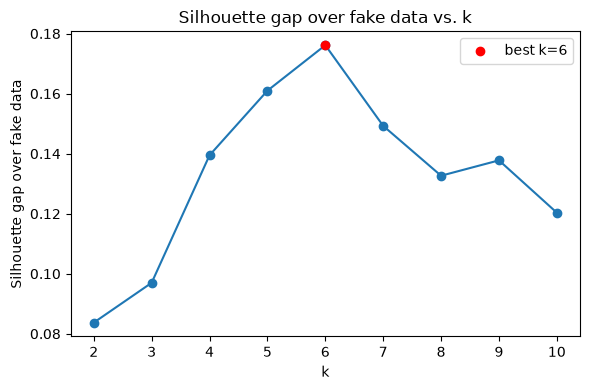

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/mall_customers_kmeans_k_selection.png')

In [5]:
from sc4020.generate_figures import plot_k_selection, show_and_save
fig = plot_k_selection(
    kmeans_tried["n_clusters"].tolist(),
    kmeans_tried["null_gap"].tolist(),
    best_k=label_free_k,
    ylabel="Silhouette gap over fake data",
)
show_and_save(fig, TOPIC, f"{DATASET_NAME}_kmeans_k_selection")

In [6]:
selections["K-Means (random init)"] = run.select_method(ds, "K-Means (random init)", selections)
results["K-Means (random init)"] = run.fit_method(
    ds, "K-Means (random init)", selections["K-Means (random init)"]
)

## 3. Clustering with K-Means++

In [7]:
results["K-Means"] = run.fit_method(ds, "K-Means", selections["K-Means"])
pd.DataFrame(
    {
        name: {
            "inertia": results[name].model.inertia_,
            "iterations": results[name].model.n_iter_,
            "fit_seconds": results[name].fit_seconds,
        }
        for name in ("K-Means (random init)", "K-Means")
    }
).T.round(3)

,inertia,iterations,fit_seconds
K-Means (random init),133.889,12.0,0.025
K-Means,133.868,6.0,0.013


## 4. Clustering with DBSCAN

min_samples follows the dimension, and eps is tried at multiples of the knee of the k-distance curve.
The rule keeps settings with at least 2 clusters and at most half the points as noise, then takes the
highest silhouette.

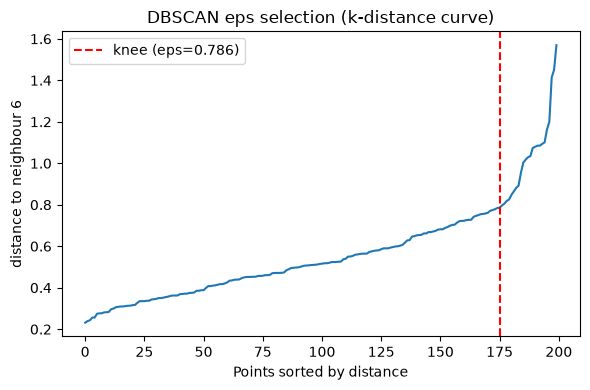

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/mall_customers_dbscan_k_distance.png')

In [8]:
from sc4020.generate_figures import plot_k_distance, show_and_save
min_samples = tuning.min_samples_from_dimension(ds.data.shape[1])
curve = tuning.k_distance_curve(ds.data, min_samples)
knee_index, eps_at_knee = tuning.find_knee(curve)
fig = plot_k_distance(curve, knee_index, eps_at_knee, min_samples)
show_and_save(fig, TOPIC, f"{DATASET_NAME}_dbscan_k_distance")

In [9]:
selections["DBSCAN"] = run.select_method(ds, "DBSCAN", max_clusters=MAX_CLUSTERS)
results["DBSCAN"] = run.fit_method(ds, "DBSCAN", selections["DBSCAN"])
print(f"chosen: {run.format_params(selections['DBSCAN'].params)}, rule satisfied: {selections['DBSCAN'].valid}")
pd.DataFrame(selections["DBSCAN"].tried).round(3)

chosen: eps=0.455, min_samples=3, rule satisfied: True


,eps,min_samples,eps_factor,n_clusters,noise_fraction,largest_cluster_share,silhouette,passes
0,0.303,3,0.50,12,0.515,0.100,0.465,False
1,0.455,3,0.75,11,0.195,0.265,0.416,True
2,0.606,3,1.00,3,0.065,0.720,0.213,True
3,0.758,3,1.25,1,0.035,0.965,NaN,False
4,0.393,6,0.50,7,0.550,0.115,0.541,False
5,0.590,6,0.75,3,0.230,0.525,0.277,True
6,0.786,6,1.00,1,0.030,0.970,NaN,False
7,0.485,12,0.50,3,0.710,0.110,0.674,False
8,0.728,12,0.75,2,0.195,0.725,0.243,True
9,0.971,12,1.00,1,0.040,0.960,NaN,False


## 5. Clustering with HDBSCAN

In [10]:
selections["HDBSCAN"] = run.select_method(ds, "HDBSCAN", max_clusters=MAX_CLUSTERS)
results["HDBSCAN"] = run.fit_method(ds, "HDBSCAN", selections["HDBSCAN"])
print(f"chosen: {run.format_params(selections['HDBSCAN'].params)}, rule satisfied: {selections['HDBSCAN'].valid}")
pd.DataFrame(selections["HDBSCAN"].tried).round(3)

chosen: min_cluster_size=5, min_samples=None, rule satisfied: True


,min_cluster_size,min_samples,n_clusters,noise_fraction,largest_cluster_share,silhouette,passes
0,5,NaN,6,0.375,0.170,0.557,True
1,5,5.0,6,0.375,0.170,0.557,True
2,5,10.0,5,0.520,0.170,0.603,False
3,10,NaN,4,0.550,0.170,0.624,False
4,10,5.0,2,0.195,0.635,0.273,True
5,10,10.0,4,0.550,0.170,0.624,False
6,15,NaN,2,0.640,0.195,0.549,False
7,15,5.0,2,0.195,0.635,0.273,True
8,15,10.0,3,0.610,0.170,0.621,False
9,20,NaN,2,0.695,0.160,0.547,False


## 6. Clustering with GMM

The number of components and the covariance type with the lowest BIC (the number of components is the
number of classes on labelled data).

In [11]:
selections["GMM"] = run.select_method(ds, "GMM", k_range=k_range)
results["GMM"] = run.fit_method(ds, "GMM", selections["GMM"])
gmm_tried = pd.DataFrame(selections["GMM"].tried).rename(columns={"score": "minus_bic"})
print(f"chosen: {run.format_params(selections['GMM'].params)}, label-free: {run.format_params(selections['GMM'].label_free)}")
gmm_tried.pivot(index="n_components", columns="covariance_type", values="minus_bic").round(1)

chosen: n_components=5, covariance_type=diag, label-free: n_components=5, covariance_type=diag


covariance_type,diag,full,spherical,tied
n_components,,,,
2,-1672.1,-1657.0,-1720.3,-1698.6
3,-1562.3,-1582.0,-1657.8,-1678.3
4,-1630.3,-1597.0,-1652.8,-1663.5
5,-1521.7,-1576.7,-1627.1,-1632.2
6,-1535.4,-1599.3,-1597.4,-1586.1
7,-1545.1,-1621.6,-1562.2,-1589.5
8,-1561.1,-1652.1,-1578.8,-1581.3
9,-1594.5,-1680.8,-1574.4,-1603.8
10,-1600.2,-1678.6,-1571.6,-1592.6


## 7. Clustering with Spectral, Agglomerative and Affinity Propagation

Spectral and Agglomerative (Ward) take the K-Means k; Affinity Propagation picks its own number of
exemplars. All three need memory quadratic in the number of points, so they are skipped on large data.

In [12]:
for name in ("Spectral", "Agglomerative", "Affinity Propagation"):
    if run.is_too_large(ds, name):
        print(f"skipping {name}: {len(ds.data):,} points is above {run.MAX_POINTS_FOR_QUADRATIC_METHODS:,}")
        continue
    selections[name] = run.select_method(ds, name, selections)
    results[name] = run.fit_method(ds, name, selections[name])
    print(f"{name}: {run.format_params(selections[name].params)}")

Spectral: n_clusters=6, affinity=rbf
Agglomerative: n_clusters=6, linkage=ward
Affinity Propagation: damping=0.9


## 8. Metrics

Internal scores (silhouette, Davies-Bouldin, DBCV) need no labels; ARI and NMI compare with the classes
when there are any. Noise points are left out of the internal scores.

In [13]:
table = run.score_methods(ds, selections, results)
run.save_dataset_run(DATASET_NAME, table, run.tried_settings(ds, selections))
columns = ["method", "params", "n_clusters", "noise_fraction", "silhouette", "davies_bouldin", "dbcv", "ari", "nmi", "fit_seconds"]
table[[column for column in columns if column in table]].round(3)

,method,params,n_clusters,noise_fraction,silhouette,davies_bouldin,dbcv,fit_seconds
0,K-Means (random init),n_clusters=6,6,0.000,0.427,0.824,0.018,0.025
1,K-Means,n_clusters=6,6,0.000,0.428,0.825,0.003,0.013
2,DBSCAN,"eps=0.455, min_samples=3",11,0.195,0.416,0.673,0.198,0.001
3,HDBSCAN,"min_cluster_size=5, min_samples=None",6,0.375,0.557,0.615,0.284,0.003
4,GMM,"n_components=5, covariance_type=diag",5,0.000,0.343,1.141,-0.091,0.017
5,Spectral,"n_clusters=6, affinity=rbf",6,0.000,0.419,0.817,-0.036,0.044
6,Agglomerative,"n_clusters=6, linkage=ward",6,0.000,0.420,0.852,0.023,0.031
7,Affinity Propagation,damping=0.9,12,0.000,0.367,0.968,-0.001,0.019


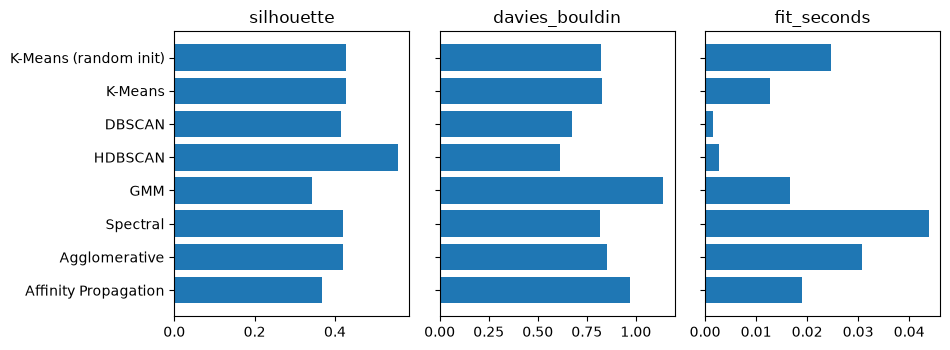

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/mall_customers_metrics.png')

In [14]:
from sc4020.generate_figures import show_and_save
metric_names = [m for m in ("silhouette", "davies_bouldin", "ari", "fit_seconds") if m in table]
fig, axes = plt.subplots(1, len(metric_names), figsize=(3.2 * len(metric_names), 3.6), sharey=True)
for ax, metric in zip(axes, metric_names):
    ax.barh(table["method"], table[metric])
    ax.set_title(metric)
axes[0].invert_yaxis()
fig.tight_layout()
show_and_save(fig, TOPIC, f"{DATASET_NAME}_metrics")

## 9. Visualization

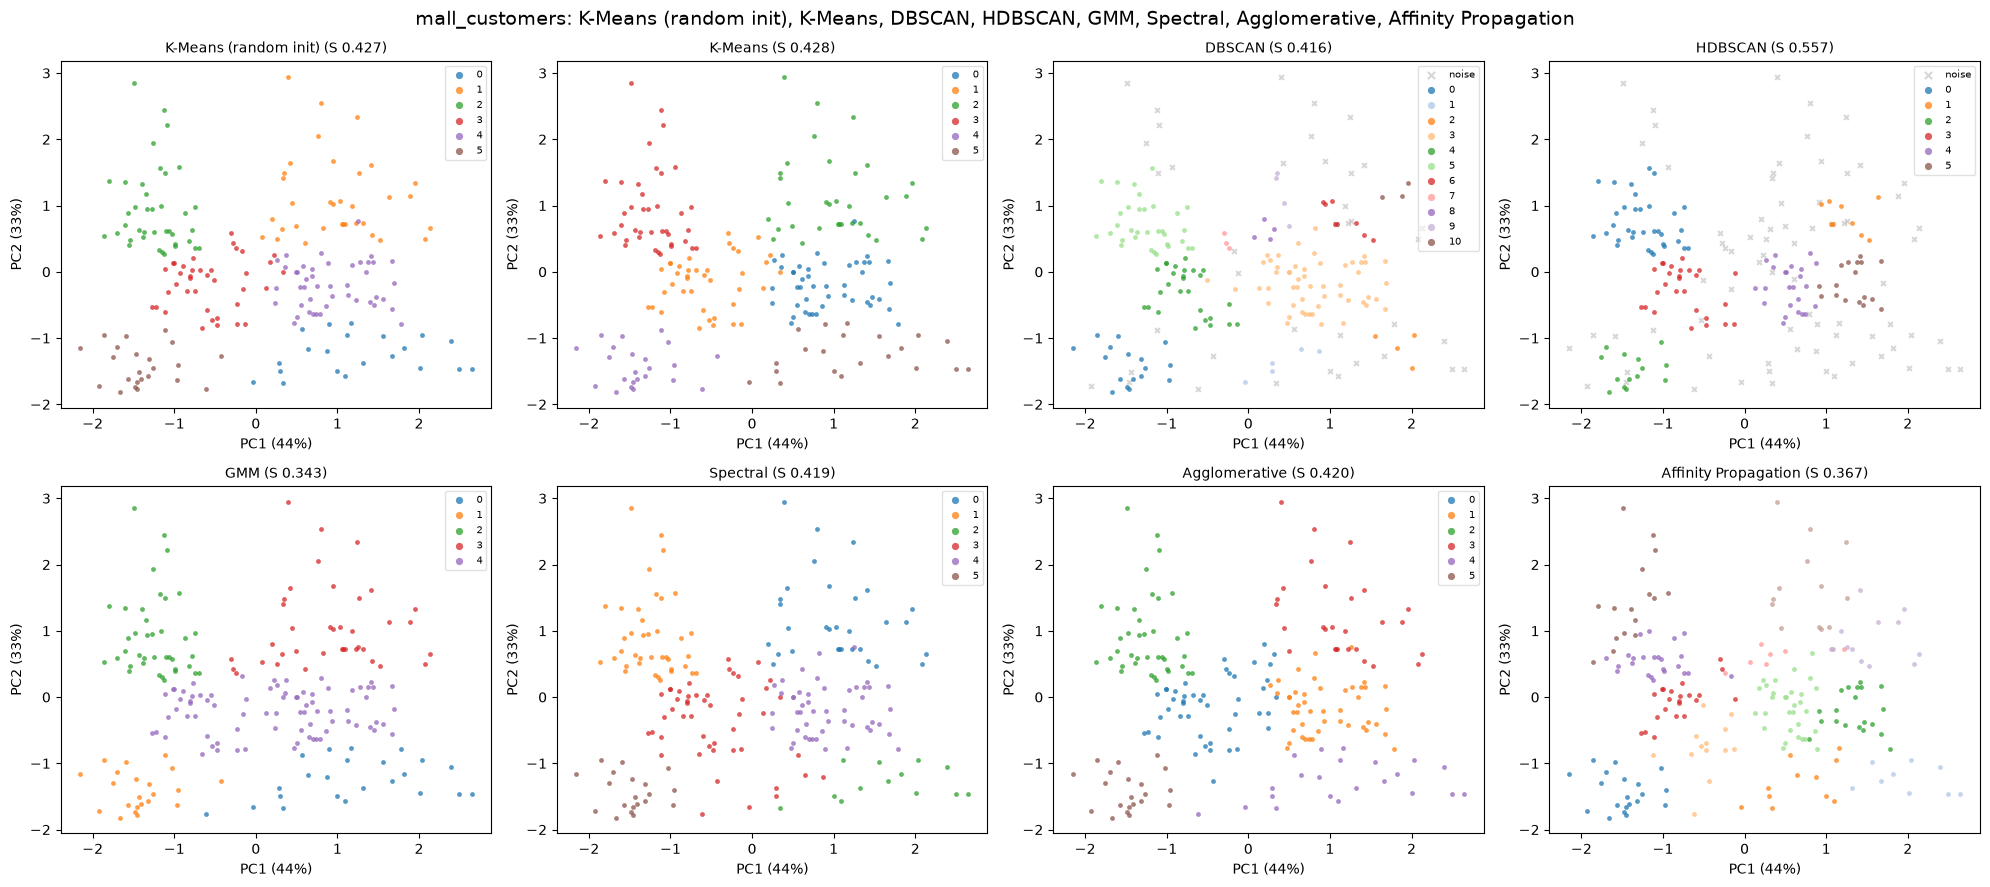

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/mall_customers_clusters.png')

In [15]:
from sc4020.generate_figures import show_and_save
fig = run.plot_dataset(ds, results, table, title=f"{DATASET_NAME}: {', '.join(results)}")
show_and_save(fig, TOPIC, f"{DATASET_NAME}_clusters")